# NSFW Image Classification Benchmark

So sánh ba model **Falconsai**, **Owen Elliott** và **NVIDIA NeMo Curator** trên cùng tập 2.000 ảnh, cân bằng theo 5 nhãn.

## 1. Cài đặt thư viện

In [1]:
# Cài các thư viện dùng cho tải dữ liệu và hai model đầu.
!pip install -q huggingface_hub transformers accelerate timm

## 2. Tải và giải nén dataset

In [2]:
from pathlib import Path
import zipfile
from huggingface_hub import hf_hub_download
from kaggle_secrets import UserSecretsClient

# Token được lưu trong Kaggle Secrets với tên HF_TOKEN.
token = UserSecretsClient().get_secret("HF_TOKEN")

zip_path = hf_hub_download(
    repo_id="deepghs/nsfw_detect",
    filename="nsfw_dataset_v1.zip",
    repo_type="dataset",
    token=token,
)

EXTRACT_DIR = Path("/kaggle/working/nsfw_dataset")
DATASET_DIR = EXTRACT_DIR / "nsfw_dataset_v1"
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

# Chỉ giải nén khi thư mục dataset chưa tồn tại.
if not DATASET_DIR.exists():
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(EXTRACT_DIR)

if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Không tìm thấy thư mục dataset: {DATASET_DIR}")

print("Dataset:", DATASET_DIR)
print("Classes:", sorted(p.name for p in DATASET_DIR.iterdir() if p.is_dir()))

nsfw_dataset_v1.zip: reconstructing file:   0%|          |  0.00B / 1.80GB            

nsfw_dataset_v1.zip: downloading bytes:           |  0.00B            

Dataset: /kaggle/working/nsfw_dataset/nsfw_dataset_v1
Classes: ['drawings', 'hentai', 'neutral', 'porn', 'sexy']


## 3. Tạo tập benchmark cố định

In [3]:
import random
import pandas as pd

LABELS = ["drawings", "hentai", "neutral", "porn", "sexy"]
SAMPLES_PER_CLASS = 400
SEED = 42
BENCHMARK_PATH = Path("/kaggle/working/benchmark_2000.csv")

# Lấy mẫu có seed để cả ba model được đánh giá trên đúng cùng ảnh.
rng = random.Random(SEED)
rows = []

for label in LABELS:
    paths = sorted((DATASET_DIR / label).glob("*.jpg"))
    if len(paths) < SAMPLES_PER_CLASS:
        raise ValueError(
            f"{label}: chỉ có {len(paths)} ảnh JPG, "
            f"cần ít nhất {SAMPLES_PER_CLASS}"
        )

    for path in rng.sample(paths, SAMPLES_PER_CLASS):
        rows.append({"image_path": str(path), "true_label": label})

benchmark_df = (
    pd.DataFrame(rows)
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)
benchmark_df.to_csv(BENCHMARK_PATH, index=False)

print("Total images:", len(benchmark_df))
display(benchmark_df["true_label"].value_counts().rename("count").to_frame())
display(benchmark_df.head())

Total images: 2000


,count
true_label,
sexy,400
drawings,400
porn,400
neutral,400
hentai,400


,image_path,true_label
0,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/s...,sexy
1,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/d...,drawings
2,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/p...,porn
3,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/n...,neutral
4,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/p...,porn


## 4. Falconsai

In [4]:
import time
import torch
from PIL import Image
from tqdm.auto import tqdm
from transformers import AutoImageProcessor, AutoModelForImageClassification

MODEL_NAME = "Falconsai/nsfw_image_detection"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = AutoModelForImageClassification.from_pretrained(
    MODEL_NAME,
    use_safetensors=True,
).to(DEVICE)
model.eval()

print("Device:", DEVICE)
print("Labels:", model.config.id2label)

preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/724 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Device: cuda
Labels: {0: 'normal', 1: 'nsfw'}


### Inference

In [5]:
id2label = {
        int(idx): str(label).lower()
        for idx, label in model.config.id2label.items()
    }
normal_idx = next(i for i, label in id2label.items() if label == "normal")
nsfw_idx = next(i for i, label in id2label.items() if label == "nsfw")

records = []
start_time = time.perf_counter()

for start in tqdm(range(0, len(benchmark_df), BATCH_SIZE)):
    batch = benchmark_df.iloc[start:start + BATCH_SIZE]
    images, valid_rows = [], []

    for row in batch.itertuples(index=False):
        try:
            with Image.open(row.image_path) as img:
                images.append(img.convert("RGB"))
            valid_rows.append(row)
        except Exception as exc:
            print(f"Skipped {row.image_path}: {exc}")

    if not images:
        continue

    inputs = processor(images=images, return_tensors="pt").to(DEVICE)
    with torch.inference_mode():
        logits = model(**inputs).logits
        probabilities = torch.softmax(logits.float(), dim=-1).cpu()

    for row, probs in zip(valid_rows, probabilities.tolist()):
        pred_idx = max(range(len(probs)), key=probs.__getitem__)
        records.append({
                "image_path": row.image_path,
                "true_label": row.true_label,
                "pred_label": id2label[pred_idx],
                "normal_score": probs[normal_idx],
                "nsfw_score": probs[nsfw_idx],
                "confidence": probs[pred_idx],
            })

falconsai_elapsed = time.perf_counter() - start_time
results = pd.DataFrame(records)
results.to_csv("/kaggle/working/falconsai_predictions.csv", index=False)

print(f"Processed: {len(results)}/{len(benchmark_df)}")
print(f"Elapsed: {falconsai_elapsed:.2f}s")
print(f"Seconds/image: {falconsai_elapsed / max(len(results), 1):.4f}")
display(results.head())

  0%|          | 0/63 [00:00<?, ?it/s]

Processed: 2000/2000
Elapsed: 31.12s
Seconds/image: 0.0156


,image_path,true_label,pred_label,normal_score,nsfw_score,confidence
0,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/s...,sexy,nsfw,0.000106,0.999894,0.999894
1,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/d...,drawings,normal,0.999613,0.000387,0.999613
2,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/p...,porn,nsfw,0.000160,0.999840,0.999840
3,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/n...,neutral,normal,0.999872,0.000128,0.999872
4,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/p...,porn,nsfw,0.000115,0.999885,0.999885


## 5. Owen Elliott

In [6]:
import timm
from timm.data import resolve_model_data_config, create_transform

OWEN_MODEL_NAME = "hf-hub:OwenElliott/image-safety-classifier-m"

owen_model = timm.create_model(OWEN_MODEL_NAME, pretrained=True).to(DEVICE)
owen_model.eval()
owen_transform = create_transform(
    **resolve_model_data_config(owen_model),
    is_training=False,
)
owen_labels = [str(label).upper() for label in owen_model.pretrained_cfg["label_names"]]

nsfw_idx_owen = owen_labels.index("NSFW")
sfw_idx_owen = owen_labels.index("SFW")
nsfl_idx_owen = owen_labels.index("NSFL")

print("Device:", DEVICE)
print("Labels:", owen_labels)

config.json:   0%|          | 0.00/918 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 45.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Device: cuda
Labels: ['NSFL', 'NSFW', 'SFW']


### Inference

In [7]:
owen_records = []
start_time = time.perf_counter()

for start in tqdm(range(0, len(benchmark_df), BATCH_SIZE)):
    batch = benchmark_df.iloc[start:start + BATCH_SIZE]
    tensors, valid_rows = [], []

    for row in batch.itertuples(index=False):
        try:
            with Image.open(row.image_path) as img:
                tensors.append(owen_transform(img.convert("RGB")))
            valid_rows.append(row)
        except Exception as exc:
            print(f"Skipped {row.image_path}: {exc}")

    if not tensors:
        continue

    inputs = torch.stack(tensors).to(DEVICE)
    with torch.inference_mode():
        probabilities = torch.softmax(
                owen_model(inputs).float(), dim=-1
        ).cpu()

    for row, probs in zip(valid_rows, probabilities.tolist()):
        pred_idx = max(range(len(probs)), key=probs.__getitem__)
        owen_records.append({
                "image_path": row.image_path,
                "true_label": row.true_label,
                "owen_pred_label": owen_labels[pred_idx],
                "owen_sfw_score": probs[sfw_idx_owen],
                "owen_nsfw_score": probs[nsfw_idx_owen],
                "owen_nsfl_score": probs[nsfl_idx_owen],
            })

owen_elapsed = time.perf_counter() - start_time
owen_results = pd.DataFrame(owen_records)
owen_results.to_csv("/kaggle/working/owen_predictions.csv", index=False)

print(f"Processed: {len(owen_results)}/{len(benchmark_df)}")
print(f"Elapsed: {owen_elapsed:.2f}s")
print(f"Seconds/image: {owen_elapsed / max(len(owen_results), 1):.4f}")
display(owen_results.head())

  0%|          | 0/63 [00:00<?, ?it/s]

Processed: 2000/2000
Elapsed: 24.78s
Seconds/image: 0.0124


,image_path,true_label,owen_pred_label,owen_sfw_score,owen_nsfw_score,owen_nsfl_score
0,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/s...,sexy,NSFW,0.032665,0.936336,0.030999
1,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/d...,drawings,NSFW,0.142661,0.811338,0.046001
2,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/p...,porn,NSFW,0.028059,0.939488,0.032454
3,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/n...,neutral,SFW,0.940117,0.029695,0.030189
4,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/p...,porn,NSFW,0.036996,0.931867,0.031138


## 6. NVIDIA NeMo Curator

In [8]:
# NeMo Curator dùng CUDA trên Kaggle; bật GPU accelerator trước khi chạy cell này.
!uv pip install "nemo-curator[image_cuda12]"

Using Python 3.13.15 environment at: /usr
Resolved 203 packages in 12.08s
Prepared 62 packages in 1m 06s
Uninstalled 30 packages in 622ms
Installed 62 packages in 216ms
 - absl-py==1.4.0
 + absl-py==2.5.1
 + aiohttp-cors==0.8.1
 + blessed==1.52.0
 + cattrs==26.2.1
 + colorful==0.5.8
 + comment-parser==1.2.5
 + cosmos-xenna==0.2.0
 - cudf-cu12==26.2.1
 + cudf-cu12==25.10.0
 - cuml-cu12==26.2.0
 + cuml-cu12==25.10.0
 - dask==2026.1.1
 + dask==2025.9.1
 - dask-cuda==26.2.0
 + dask-cuda==25.10.0
 - dask-cudf-cu12==26.2.1
 + dask-cudf-cu12==25.10.0
 + distlib==0.4.4
 - distributed==2026.1.1
 + distributed==2025.9.1
 - distributed-ucxx-cu12==0.48.0
 + distributed-ucxx-cu12==0.46.0
 + gpustat==1.1.1
 + hydra-core==1.3.7
 + jinxed==2.1.0
 + libcst==1.9.0
 - libcudf-cu12==26.2.1
 + libcudf-cu12==25.10.0
 - libcugraph-cu12==26.2.0
 + libcugraph-cu12==25.10.1
 - libcuml-cu12==26.2.0
 + libcuml-cu12==25.10.0
 - libkvikio-cu12==26.2.0
 + libkvikio-cu12==25.10.0
 - libraft-cu12==26.2.0
 + libraft-cu

In [9]:
import importlib.metadata as metadata
import sys

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("NeMo Curator:", metadata.version("nemo-curator"))
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.15
PyTorch: 2.11.0+cu128
CUDA available: True
NeMo Curator: 1.3.0
GPU: Tesla T4


### Compatibility fix và inference

In [10]:
import numpy as np
from pathlib import Path
from nemo_curator.tasks import ImageObject, ImageBatch
from nemo_curator.models.clip import CLIPImageEmbeddings
from nemo_curator.models.nsfw import NSFWScorer
from nemo_curator.stages.image.embedders.clip_embedder import ImageEmbeddingStage
from nemo_curator.stages.image.filters.nsfw_filter import ImageNSFWFilterStage

    # Transformers 5.x trả BaseModelOutputWithPooling từ get_image_features().
    # NeMo Curator 1.3.0 mong đợi Tensor; vì vậy lấy pooled features, chiếu
    # bằng visual_projection rồi L2-normalize để tạo embedding CLIP 768 chiều.
@torch.no_grad()
def patched_clip_call(self, images):
    if isinstance(images, np.ndarray):
        images = torch.from_numpy(images).permute(0, 3, 1, 2).to(self.device)
        pixel_values = self.transforms(images)
    else:
        pixel_values = self.processor(
                images=images, return_tensors="pt"
        )["pixel_values"].to(self.device)

    vision_outputs = self.clip.vision_model(
            pixel_values=pixel_values,
            return_dict=True,
    )
    embeddings = self.clip.visual_projection(vision_outputs.pooler_output)
    return embeddings / torch.linalg.vector_norm(
            embeddings, dim=-1, keepdim=True
    ).clamp_min(1e-12)

CLIPImageEmbeddings.__call__ = patched_clip_call

MODEL_DIR = Path("/kaggle/working/nemo_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_dir = str(MODEL_DIR)

    # Tải weights vào thư mục local để stage dùng lại.
CLIPImageEmbeddings.download_weights_on_node(model_dir)
NSFWScorer.download_weights_on_node(model_dir)

embedding_stage = ImageEmbeddingStage(
        model_dir=model_dir,
        model_inference_batch_size=16,
        num_gpus_per_worker=1,
        verbose=True,
)
nsfw_stage = ImageNSFWFilterStage(
        model_dir=model_dir,
        model_inference_batch_size=32,
        num_gpus_per_worker=1,
        score_threshold=1.1,  # Cao hơn score tối đa để không loại ảnh khỏi benchmark.
        verbose=True,
)

embedding_stage.setup()
nsfw_stage.setup()

NEMO_BATCH_SIZE = 64
nemo_records = []
start_time = time.perf_counter()

for start in range(0, len(benchmark_df), NEMO_BATCH_SIZE):
    chunk = benchmark_df.iloc[start:start + NEMO_BATCH_SIZE]
    objects = []

    for idx, row in chunk.iterrows():
        with Image.open(row["image_path"]) as img:
            image_array = np.asarray(img.convert("RGB"))

        objects.append(ImageObject(
                image_path=str(row["image_path"]),
                image_id=str(idx),
                metadata={"true_label": row["true_label"]},
                image_data=image_array,
        ))

    task = ImageBatch(dataset_name="nsfw_benchmark_2000", data=objects)
    task = embedding_stage.process(task)
    task = nsfw_stage.process(task)

    for obj in task.data:
        nemo_records.append({
                "image_path": obj.image_path,
                "true_label": obj.metadata["true_label"],
                "nemo_nsfw_score": obj.nsfw_score,
        })

    print(f"Processed: {len(nemo_records)}/{len(benchmark_df)}")

nemo_elapsed = time.perf_counter() - start_time
nemo_results = pd.DataFrame(nemo_records)
nemo_results.to_csv("/kaggle/working/nemo_predictions.csv", index=False)

print(f"Processed: {len(nemo_results)}/{len(benchmark_df)}")
print("Missing scores:", nemo_results["nemo_nsfw_score"].isna().sum())
print(f"Elapsed: {nemo_elapsed:.2f}s")
print(f"Seconds/image: {nemo_elapsed / max(len(nemo_results), 1):.4f}")
display(nemo_results.head())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

2026-10-21 06:44:50.559 | INFO     | nemo_curator.models.clip:download_weights_on_node:140 - CLIPImageEmbeddings weights downloaded to: /kaggle/working/nemo_models/openai/clip-vit-large-patch14


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

2026-10-21 06:44:54.904 | INFO     | nemo_curator.stages.image.embedders.clip_embedder:setup:68 - Initialized CLIP model for image embedding generation
2026-10-21 06:44:54.922 | INFO     | nemo_curator.stages.image.filters.nsfw_filter:setup:51 - Initialized NSFW scoring model
/usr/local/lib/python3.13/dist-packages/transformers/image_processing_backends.py:135: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  image = torch.from_numpy(image).contiguous()
2026-10-21 06:44:56.245 | INFO     | nemo_curator.stages.image.embedders.clip_embedder:process:114 - Generated embeddings for 16 images.
2026-10-21 06:44:57.213 | INFO 

...

2026-10-21 06:47:04.967 | INFO     | nemo_curator.stages.image.embedders.clip_embedder:process:114 - Generated embeddings for 16 images.
2026-10-21 06:47:05.983 | INFO     | nemo_curator.stages.image.embedders.clip_embedder:process:114 - Generated embeddings for 16 images.
2026-10-21 06:47:06.999 | INFO     | nemo_curator.stages.image.embedders.clip_embedder:process:114 - Generated embeddings for 16 images.
2026-10-21 06:47:08.014 | INFO     | nemo_curator.stages.image.embedders.clip_embedder:process:114 - Generated embeddings for 16 images.
2026-10-21 06:47:08.016 | INFO     | nemo_curator.stages.image.filters.nsfw_filter:process:78 - Generated NSFW scores for 32 images in batch 31-63
2026-10-21 06:47:08.018 | INFO     | nemo_curator.stages.image.filters.nsfw_filter:process:78 - Generated NSFW scores for 32 images in batch 31-63
2026-10-21 06:47:08.019 | INFO     | nemo_curator.stages.image.filters.nsfw_filter:process:98 - NSFW filtering: 64/64 images passed, 0 filtered out


Processed: 1984/2000


2026-10-21 06:47:09.091 | INFO     | nemo_curator.stages.image.embedders.clip_embedder:process:114 - Generated embeddings for 16 images.
2026-10-21 06:47:09.093 | INFO     | nemo_curator.stages.image.filters.nsfw_filter:process:78 - Generated NSFW scores for 16 images in batch 15-47
2026-10-21 06:47:09.094 | INFO     | nemo_curator.stages.image.filters.nsfw_filter:process:98 - NSFW filtering: 16/16 images passed, 0 filtered out


Processed: 2000/2000
Processed: 2000/2000
Missing scores: 0
Elapsed: 134.17s
Seconds/image: 0.0671


,image_path,true_label,nemo_nsfw_score
0,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/s...,sexy,0.996499
1,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/d...,drawings,0.003637
2,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/p...,porn,0.999999
3,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/n...,neutral,0.000004
4,/kaggle/working/nsfw_dataset/nsfw_dataset_v1/p...,porn,0.999995


## 7. So sánh metric

,model,n_images,ROC_AUC,PR_AUC_AP,Precision@0.5,Recall@0.5,F1@0.5,Accuracy@0.5,elapsed_seconds,seconds_per_image
2,NeMo Curator,2000,0.9970,0.9981,0.9848,0.9700,0.9773,0.9730,134.1719,0.0671
0,Falconsai,2000,0.9757,0.9859,0.9910,0.8283,0.9024,0.8925,31.1202,0.0156
1,Owen Elliott,2000,0.9494,0.9585,0.8971,0.9158,0.9064,0.8865,24.7791,0.0124



Falconsai — rows=true [SFW, NSFW], columns=predicted [SFW, NSFW]
[[791   9]
 [206 994]]

Owen Elliott — rows=true [SFW, NSFW], columns=predicted [SFW, NSFW]
[[ 674  126]
 [ 101 1099]]

NeMo Curator — rows=true [SFW, NSFW], columns=predicted [SFW, NSFW]
[[ 782   18]
 [  36 1164]]


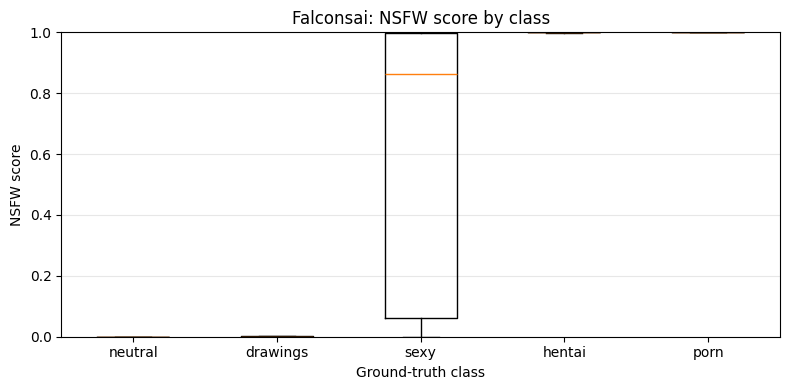

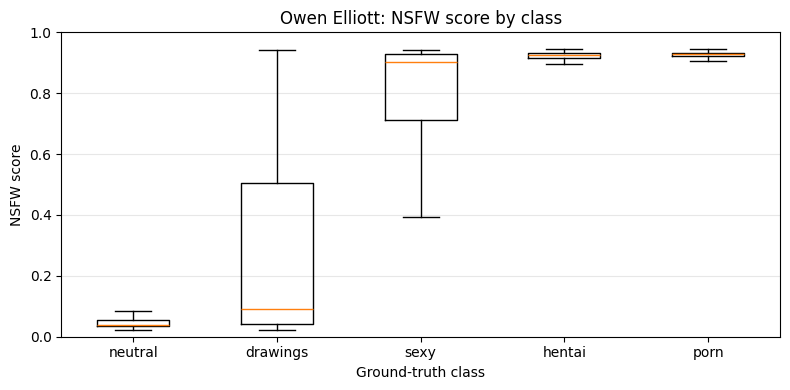

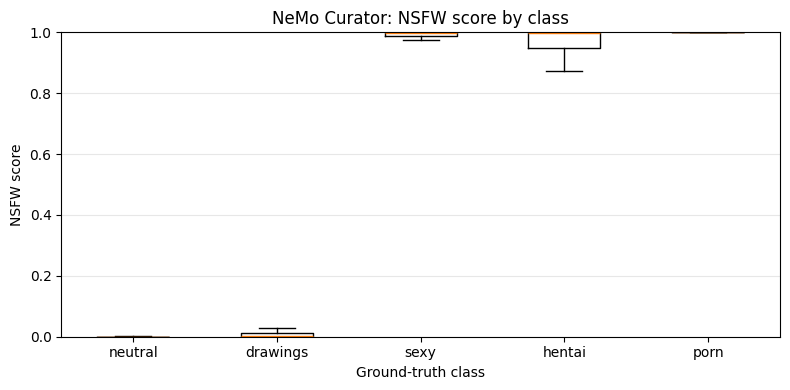

Saved benchmark summary and merged predictions.


In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
)

BASE = "/kaggle/working"
FILES = {
    "Falconsai": f"{BASE}/falconsai_predictions.csv",
    "Owen Elliott": f"{BASE}/owen_predictions.csv",
    "NeMo Curator": f"{BASE}/nemo_predictions.csv",
}
SCORE_COLUMNS = {
    "Falconsai": "nsfw_score",
    "Owen Elliott": "owen_nsfw_score",
    "NeMo Curator": "nemo_nsfw_score",
}

# Quy ước nhị phân cần giữ nhất quán trong toàn bộ benchmark.
NSFW_LABELS = {"porn", "hentai", "sexy"}
SFW_LABELS = {"neutral", "drawings"}
THRESHOLD = 0.5
ELAPSED_SECONDS = {
    "Falconsai": falconsai_elapsed,
    "Owen Elliott": owen_elapsed,
    "NeMo Curator": nemo_elapsed,
}

frames = {}
for name, path in FILES.items():
    df = pd.read_csv(path)
    score_col = SCORE_COLUMNS[name]
    required = {"image_path", "true_label", score_col}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{name}: thiếu cột {missing}")

    df = df[["image_path", "true_label", score_col]].copy()
    df["true_label"] = df["true_label"].astype(str).str.lower().str.strip()
    df[score_col] = pd.to_numeric(df[score_col], errors="coerce")

    if df["image_path"].duplicated().any():
        raise ValueError(f"{name}: image_path bị trùng")
    frames[name] = df

# Inner join bảo đảm chỉ đánh giá những ảnh có kết quả ở cả ba model.
merged = frames["Falconsai"].rename(
    columns={"true_label": "label_f", "nsfw_score": "Falconsai_score"}
).merge(
    frames["Owen Elliott"].rename(
        columns={"true_label": "label_o", "owen_nsfw_score": "Owen Elliott_score"}
    ),
    on="image_path",
    validate="one_to_one",
).merge(
    frames["NeMo Curator"].rename(
        columns={"true_label": "label_n", "nemo_nsfw_score": "NeMo Curator_score"}
    ),
    on="image_path",
    validate="one_to_one",
)

if not (
    (merged["label_f"] == merged["label_o"])
    & (merged["label_o"] == merged["label_n"])
).all():
    raise ValueError("Nhãn ground truth không nhất quán giữa các file.")

merged = merged.rename(columns={"label_f": "ground_truth"})
merged["ground_truth"] = merged["ground_truth"].str.lower().str.strip()
unknown = set(merged["ground_truth"]) - NSFW_LABELS - SFW_LABELS
if unknown:
    raise ValueError(f"Nhãn chưa được định nghĩa: {sorted(unknown)}")

merged["y_true"] = merged["ground_truth"].isin(NSFW_LABELS).astype(int)
score_map = {
    "Falconsai": "Falconsai_score",
    "Owen Elliott": "Owen Elliott_score",
    "NeMo Curator": "NeMo Curator_score",
}

summary_rows = []
confusion_matrices = {}

for name, score_col in score_map.items():
    scores = merged[score_col].to_numpy(dtype=float)
    y_true = merged["y_true"].to_numpy()

    if not np.isfinite(scores).all():
        raise ValueError(f"{name}: có score thiếu hoặc không hữu hạn")

    y_pred = (scores >= THRESHOLD).astype(int)
    summary_rows.append({
        "model": name,
        "n_images": len(y_true),
        "ROC_AUC": roc_auc_score(y_true, scores),
        "PR_AUC_AP": average_precision_score(y_true, scores),
        f"Precision@{THRESHOLD}": precision_score(y_true, y_pred, zero_division=0),
        f"Recall@{THRESHOLD}": recall_score(y_true, y_pred, zero_division=0),
        f"F1@{THRESHOLD}": f1_score(y_true, y_pred, zero_division=0),
        f"Accuracy@{THRESHOLD}": accuracy_score(y_true, y_pred),
        "elapsed_seconds": ELAPSED_SECONDS[name],
        "seconds_per_image": ELAPSED_SECONDS[name] / len(y_true),
    })
    confusion_matrices[name] = confusion_matrix(y_true, y_pred, labels=[0, 1])

summary_df = pd.DataFrame(summary_rows).sort_values("ROC_AUC", ascending=False)
display(summary_df.round(4))

for name, matrix in confusion_matrices.items():
    print(f"\n{name} — rows=true [SFW, NSFW], columns=predicted [SFW, NSFW]")
    print(matrix)

# Phân bố score theo từng lớp giúp phát hiện lớp nào khó phân loại.
class_order = ["neutral", "drawings", "sexy", "hentai", "porn"]
for name, score_col in score_map.items():
    plt.figure(figsize=(8, 4))
    values = [
        merged.loc[merged["ground_truth"] == label, score_col].dropna()
        for label in class_order
    ]
    plt.boxplot(values, tick_labels=class_order, showfliers=False)
    plt.title(f"{name}: NSFW score by class")
    plt.xlabel("Ground-truth class")
    plt.ylabel("NSFW score")
    plt.ylim(0, 1)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

summary_df.to_csv(f"{BASE}/nsfw_benchmark_summary.csv", index=False)
merged.to_csv(f"{BASE}/nsfw_benchmark_merged.csv", index=False)
print("Saved benchmark summary and merged predictions.")

## 8. Tìm ngưỡng tối ưu F1 (tham khảo)

In [12]:
from sklearn.metrics import precision_recall_curve

# Chỉ dùng để khảo sát trên benchmark này; không xem đây là kết quả test độc lập.
threshold_rows = []
y_true = merged["y_true"].to_numpy()

for model_name, score_col in score_map.items():
    scores = merged[score_col].to_numpy(dtype=float)
    precision, recall, thresholds = precision_recall_curve(y_true, scores)

    # precision/recall có thêm một phần tử cuối không tương ứng với threshold.
    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )
    best_idx = int(np.argmax(f1_values))

    threshold_rows.append({
        "model": model_name,
        "best_threshold": thresholds[best_idx],
        "precision_at_best": precision[best_idx],
        "recall_at_best": recall[best_idx],
        "best_F1": f1_values[best_idx],
    })

threshold_df = pd.DataFrame(threshold_rows).sort_values("best_F1", ascending=False)
display(threshold_df.round(4))
threshold_df.to_csv("/kaggle/working/nsfw_optimal_thresholds.csv", index=False)

,model,best_threshold,precision_at_best,recall_at_best,best_F1
2,NeMo Curator,0.2557,0.9809,0.9858,0.9834
0,Falconsai,0.0064,0.9479,0.9408,0.9444
1,Owen Elliott,0.3570,0.8874,0.9325,0.9094


## 9. Bộ file kết quả và biểu đồ chi tiết

Mục này tạo lại từ `merged` (Mục 7) bộ file CSV và biểu đồ chi tiết cho ba model: `quality_metrics.csv`, `per_class_metrics.csv`, `performance_metrics.csv`, `confusion_matrices.png`, `roc_pr_curves.png`. Tất cả được lưu vào `BASE` (`/kaggle/working`). Cần chạy Mục 7 trước.

### 9.1 Chất lượng phân loại (`quality_metrics.csv`)

,model,n_images,threshold,accuracy,precision,recall,f1,ROC_AUC,PR_AUC_AP,TN,FP,FN,TP
0,Falconsai,2000,0.5,0.8925,0.9910,0.8283,0.9024,0.9757,0.9859,791,9,206,994
1,Owen Elliott,2000,0.5,0.8865,0.8971,0.9158,0.9064,0.9494,0.9585,674,126,101,1099
2,NeMo Curator,2000,0.5,0.9730,0.9848,0.9700,0.9773,0.9970,0.9981,782,18,36,1164


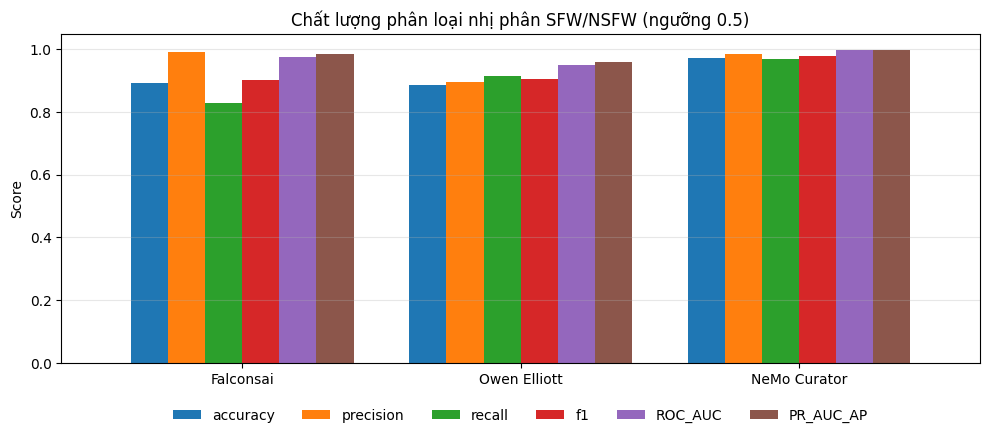

In [13]:
from sklearn.metrics import roc_curve

MODELS = list(score_map)
y_true = merged["y_true"].to_numpy()

quality_rows = []
for name, score_col in score_map.items():
    scores = merged[score_col].to_numpy(dtype=float)
    y_pred = (scores >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    quality_rows.append({
        "model": name,
        "n_images": len(y_true),
        "threshold": THRESHOLD,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, scores),
        "PR_AUC_AP": average_precision_score(y_true, scores),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })

quality_df = pd.DataFrame(quality_rows).round(4)
quality_df.to_csv(f"{BASE}/quality_metrics.csv", index=False)
display(quality_df)

metric_cols = ["accuracy", "precision", "recall", "f1", "ROC_AUC", "PR_AUC_AP"]
ax = quality_df.set_index("model")[metric_cols].plot.bar(figsize=(10, 4.5), rot=0, width=0.8)
ax.set_ylim(0, 1.05)
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_title(f"Chất lượng phân loại nhị phân SFW/NSFW (ngưỡng {THRESHOLD})")
ax.grid(axis="y", alpha=0.3)
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout()
plt.show()

### 9.2 Confusion matrix (`confusion_matrices.png`)

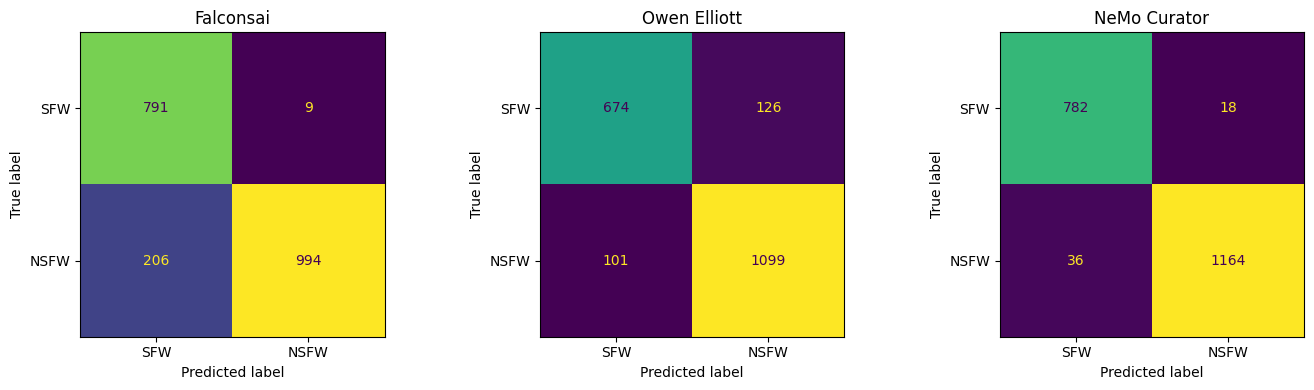

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, len(MODELS), figsize=(14, 4))
for ax, name in zip(axes, MODELS):
    ConfusionMatrixDisplay(
        confusion_matrices[name], display_labels=["SFW", "NSFW"]
    ).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
fig.savefig(f"{BASE}/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

### 9.3 Đường ROC và Precision–Recall (`roc_pr_curves.png`)

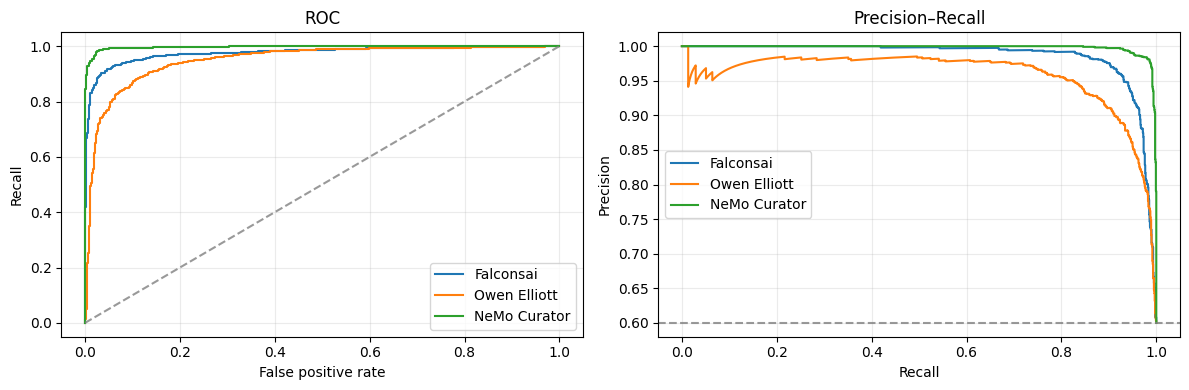

In [15]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 4))

for name, score_col in score_map.items():
    scores = merged[score_col].to_numpy(dtype=float)
    fpr, tpr, _ = roc_curve(y_true, scores)
    precision, recall, _ = precision_recall_curve(y_true, scores)
    ax_roc.plot(fpr, tpr, label=name)
    ax_pr.plot(recall, precision, label=name)

ax_roc.plot([0, 1], [0, 1], "--", color="gray", alpha=0.8)
ax_roc.set_title("ROC")
ax_roc.set_xlabel("False positive rate")
ax_roc.set_ylabel("Recall")

# Đường nền của PR là tỉ lệ ảnh NSFW trong tập benchmark.
ax_pr.axhline(y_true.mean(), linestyle="--", color="gray", alpha=0.8)
ax_pr.set_title("Precision–Recall")
ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")

for ax in (ax_roc, ax_pr):
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
fig.savefig(f"{BASE}/roc_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### 9.4 Kết quả theo từng lớp (`per_class_metrics.csv`)

Với lớp SFW (`neutral`, `drawings`), tỉ lệ dự đoán NSFW chính là tỉ lệ báo nhầm, càng thấp càng tốt. Với lớp NSFW (`sexy`, `hentai`, `porn`), đó là recall của lớp, càng cao càng tốt.

,model,class,n_images,NSFW_prediction_rate,binary_accuracy,mean_score
0,Falconsai,neutral,400,0.0025,0.9975,0.0067
1,Falconsai,drawings,400,0.0200,0.9800,0.0264
2,Falconsai,sexy,400,0.5800,0.5800,0.5867
3,Falconsai,hentai,400,0.9300,0.9300,0.9300
4,Falconsai,porn,400,0.9750,0.9750,0.9717
5,Owen Elliott,neutral,400,0.0625,0.9375,0.0998
6,Owen Elliott,drawings,400,0.2525,0.7475,0.2820
7,Owen Elliott,sexy,400,0.8200,0.8200,0.7524
8,Owen Elliott,hentai,400,0.9650,0.9650,0.8889
9,Owen Elliott,porn,400,0.9625,0.9625,0.8912


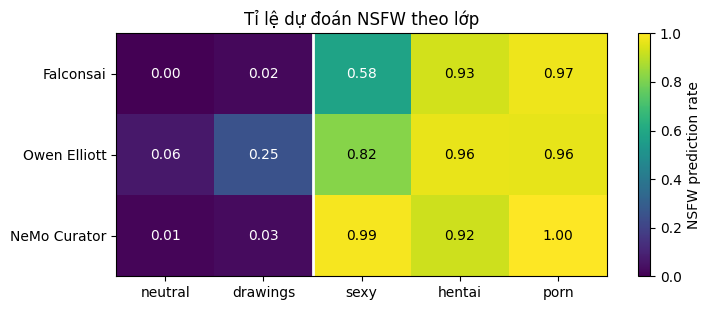

In [16]:
class_order = ["neutral", "drawings", "sexy", "hentai", "porn"]

per_class_rows = []
for name, score_col in score_map.items():
    for label in class_order:
        subset = merged.loc[merged["ground_truth"] == label, score_col].to_numpy(dtype=float)
        nsfw_rate = float((subset >= THRESHOLD).mean())
        per_class_rows.append({
            "model": name,
            "class": label,
            "n_images": len(subset),
            "NSFW_prediction_rate": nsfw_rate,
            "binary_accuracy": nsfw_rate if label in NSFW_LABELS else 1 - nsfw_rate,
            "mean_score": float(subset.mean()),
        })

per_class_df = pd.DataFrame(per_class_rows).round(4)
per_class_df.to_csv(f"{BASE}/per_class_metrics.csv", index=False)
display(per_class_df)

rate = per_class_df.pivot(
    index="model", columns="class", values="NSFW_prediction_rate"
).loc[MODELS, class_order]

fig, ax = plt.subplots(figsize=(7.5, 3.2))
im = ax.imshow(rate.to_numpy(), vmin=0, vmax=1, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(class_order)), class_order)
ax.set_yticks(range(len(MODELS)), MODELS)
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        value = rate.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                color="black" if value > 0.6 else "white")
ax.axvline(1.5, color="white", linewidth=2)  # tách nhóm SFW (trái) và NSFW (phải)
ax.set_title("Tỉ lệ dự đoán NSFW theo lớp")
fig.colorbar(im, ax=ax, label="NSFW prediction rate")
plt.tight_layout()
plt.show()

### 9.5 Hiệu năng (`performance_metrics.csv`)

Số liệu lấy từ thời gian chạy inference theo batch ở các mục 4–6. Notebook không đo độ trễ từng ảnh (p50/p95), số tham số, dung lượng checkpoint hay RAM, nên các cột đó không có trong file này.

,model,device,batch_size,n_images,measured_seconds,mean_ms_per_image,images_per_second
0,Falconsai,cuda,32,2000,31.120,15.560,64.267
1,Owen Elliott,cuda,32,2000,24.779,12.390,80.713
2,NeMo Curator,cuda,64,2000,134.172,67.086,14.906


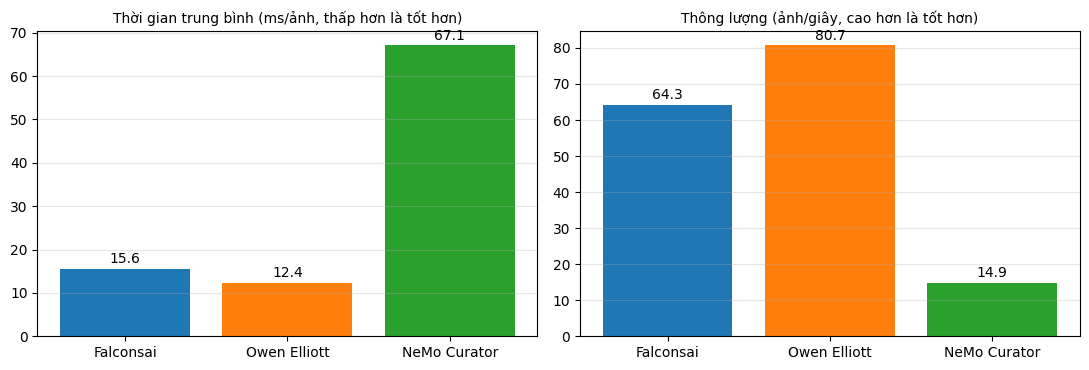

In [17]:
BATCH_SIZES = {
    "Falconsai": BATCH_SIZE,
    "Owen Elliott": BATCH_SIZE,
    "NeMo Curator": NEMO_BATCH_SIZE,
}

performance_rows = []
for name in MODELS:
    seconds = ELAPSED_SECONDS[name]
    performance_rows.append({
        "model": name,
        "device": str(DEVICE),
        "batch_size": BATCH_SIZES[name],
        "n_images": len(y_true),
        "measured_seconds": seconds,
        "mean_ms_per_image": seconds / len(y_true) * 1000,
        "images_per_second": len(y_true) / seconds,
    })

performance_df = pd.DataFrame(performance_rows).round(3)
performance_df.to_csv(f"{BASE}/performance_metrics.csv", index=False)
display(performance_df)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title in [
    (axes[0], "mean_ms_per_image", "Thời gian trung bình (ms/ảnh, thấp hơn là tốt hơn)"),
    (axes[1], "images_per_second", "Thông lượng (ảnh/giây, cao hơn là tốt hơn)"),
]:
    bars = ax.bar(performance_df["model"], performance_df[col], color=["#1f77b4", "#ff7f0e", "#2ca02c"])
    ax.bar_label(bars, fmt="%.1f", padding=2)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()